# FinMark Data Preprocessing
This notebook contains preprocessing steps for Customer Segments, Transactions, and Social Media datasets.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load cleaned files
segments = pd.read_csv("Cleaned_Customer_Demographics.csv")
transactions = pd.read_csv("Cleaned_Customer_Transactions.csv")
social = pd.read_csv("Cleaned_Social_Media_Interactions.csv")

In [2]:
# Age distribution
print(segments['Age'].describe())
print("Mode:", segments['Age'].mode().values)

# Transaction amounts
print(transactions['Amount'].describe())
print("Mode:", transactions['Amount'].mode().values)

count    3000.000000
mean       44.679667
std        14.437054
min        18.000000
25%        34.000000
50%        45.000000
75%        57.000000
max        70.000000
Name: Age, dtype: float64
Mode: [45.]
count    3000.000000
mean      494.009073
std       279.371704
min         0.000000
25%       257.467500
50%       498.080000
75%       721.662500
max       999.860000
Name: Amount, dtype: float64
Mode: [498.08]


In [3]:
print(segments['IncomeLevel'].value_counts())
print(transactions['ProductCategory'].value_counts())
print(transactions['PaymentMethod'].value_counts())
print(social['Platform'].value_counts())
print(social['Sentiment'].value_counts())

IncomeLevel
High       935
Low        918
Medium     863
Unknown    284
Name: count, dtype: int64
ProductCategory
Clothing           568
Electronics        561
Automotive         538
Home & Garden      529
Health & Beauty    524
Unknown            280
Name: count, dtype: int64
PaymentMethod
Debit Card       762
Credit Card      753
PayPal           747
Bank Transfer    738
Name: count, dtype: int64
Platform
Instagram    916
Twitter      907
Facebook     887
Unknown      290
Name: count, dtype: int64
Sentiment
Positive         898
Neutral          870
Negative         861
Unknown          308
Very Negative     32
Very Positive     31
Name: count, dtype: int64


In [4]:
q1 = transactions['Amount'].quantile(0.25)
q3 = transactions['Amount'].quantile(0.75)
iqr = q3 - q1
outliers = transactions[(transactions['Amount'] < (q1 - 1.5*iqr)) | (transactions['Amount'] > (q3 + 1.5*iqr))]
print(outliers)

Empty DataFrame
Columns: [CustomerID, TransactionID, TransactionDate, Amount, ProductCategory, PaymentMethod]
Index: []


In [5]:
# Merge demographics + transactions
merged = pd.merge(transactions, segments, on="CustomerID", how="inner")

# Spending by income level
print(merged.groupby("IncomeLevel")['Amount'].mean())

# Spending by age group
merged['AgeGroup'] = pd.cut(merged['Age'], bins=[0,25,40,60,100], labels=['Youth','Young Adult','Adult','Senior'])
print(merged.groupby("AgeGroup")['Amount'].mean())

IncomeLevel
High       493.026828
Low        495.999423
Medium     492.677661
Unknown    495.205849
Name: Amount, dtype: float64
AgeGroup
Youth          474.454036
Young Adult    483.992103
Adult          499.553275
Senior         508.022524
Name: Amount, dtype: float64


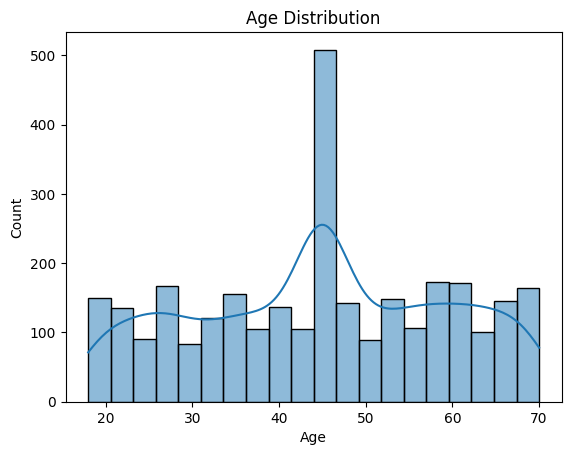

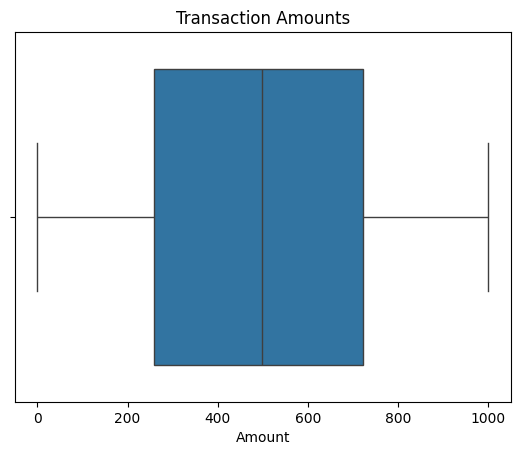

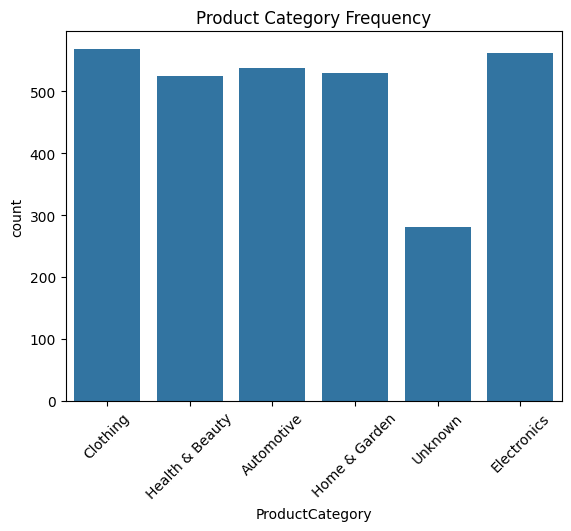

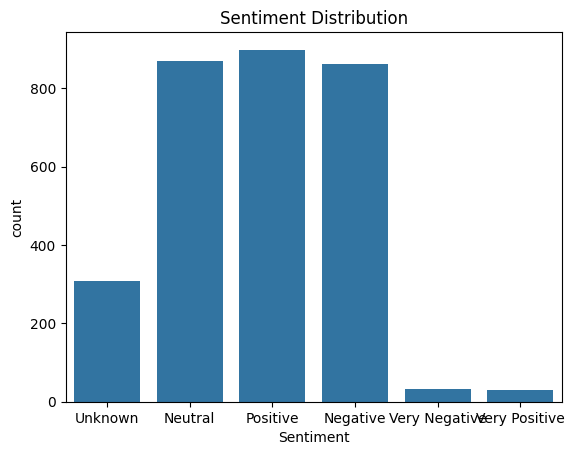

In [ ]:
# Histogram of Age
sns.histplot(segments['Age'], bins=20, kde=True)
plt.title("Age Distribution")
plt.show()

# Boxplot of Transaction Amounts
sns.boxplot(x=transactions['Amount'])
plt.title("Transaction Amounts")
plt.show()

# Bar chart of Product Categories 1
sns.countplot(x=transactions['ProductCategory'])
plt.title("Product Category Frequency")
plt.xticks(rotation=45)
plt.show()

# Sentiment distribution
sns.countplot(x=social['Sentiment'])
plt.title("Sentiment Distribution")
plt.show()

In [10]:
# Raw counts (before cleaning)
#for testing counts

raw_transactions = pd.read_csv("customer_transactions_contaminated.csv")
print(raw_transactions['ProductCategory'].value_counts())

# Cleaned counts (after cleaning)
clean_transactions = pd.read_csv("Cleaned_Customer_Transactions.csv")
print(clean_transactions['ProductCategory'].value_counts())

ProductCategory
Clothing           598
Electronics        595
Automotive         576
Health & Beauty    570
Home & Garden      562
Name: count, dtype: int64
ProductCategory
Clothing           568
Electronics        561
Automotive         538
Home & Garden      529
Health & Beauty    524
Unknown            280
Name: count, dtype: int64
